# I. Load data from .e

In [5]:
from read_fem import *

In [6]:
geo_model_name = "ell"
if geo_model_name == "fell":
    output_list_initd = [
        [
            'simulation_outputs/the11.e','simulation_outputs/the9.e','simulation_outputs/the13.e','simulation_outputs/the15.e'
        ],
        [
            r"No Prescribed Damage",
            r"Prescribed Damage at Depth $\approx 0.02\,$m",
            r"Prescribed Damage at Depth $\approx 0.05\,$m",
            r"Vertical Initial Cracks",
        ]
    ]
else:
    output_list_initd = [
        [
            'simulation_outputs/the12.e','simulation_outputs/the10.e','simulation_outputs/the14.e','simulation_outputs/the16.e'
        ],
        [
            r"No Prescribed Damage",
            r"Prescribed Damage at Depth $\approx 0.02\,$m",
            r"Prescribed Damage at Depth $\approx 0.05\,$m",
            r"Vertical Initial Cracks",
        ]
    ]

In [7]:



output_list=[output_list_initd[0],output_list_initd[1]]
node_variable_idx=[1, 2 ,3 ,4]
node_var_labels=[[r"Temperature $\theta\;(^{\circ}C)$", ""],
                 [r"Phase Field Fracture Damage", ""],
                 [r"Displacement $u_x$ (m)", ""],
                 [r"Displacement $u_y$ (m)", ""]]

element_variable_idx=[3,]#12]
elt_var_labels=[[r"Energy Release Rate $G_c(x,y)$ MPa $\cdot$m", ""],
                ]
output_list

[['simulation_outputs/the12.e',
  'simulation_outputs/the10.e',
  'simulation_outputs/the14.e',
  'simulation_outputs/the16.e'],
 ['No Prescribed Damage',
  'Prescribed Damage at Depth $\\approx 0.02\\,$m',
  'Prescribed Damage at Depth $\\approx 0.05\\,$m',
  'Vertical Initial Cracks']]

In [8]:
#nodes, connect_components, global_connection, node_vars, elet_vars,times=read_vars(e_name, node_variable_idx, element_variable_idx)
profiles = [read_vars(e_name, node_variable_idx, element_variable_idx) for e_name in output_list[0]]

['time_whole', 'eb_status', 'eb_prop1', 'ns_status', 'ns_prop1', 'ss_status', 'ss_prop1', 'coordx', 'coordy', 'eb_names', 'ns_names', 'ss_names', 'coor_names', 'node_num_map', 'connect1', 'connect2', 'elem_num_map', 'elem_ss1', 'side_ss1', 'elem_ss2', 'side_ss2', 'elem_ss3', 'side_ss3', 'elem_ss4', 'side_ss4', 'elem_ss5', 'side_ss5', 'node_ns1', 'node_ns2', 'node_ns3', 'node_ns4', 'node_ns5', 'name_nod_var', 'vals_nod_var1', 'vals_nod_var2', 'vals_nod_var3', 'vals_nod_var4', 'name_elem_var', 'vals_elem_var1eb1', 'vals_elem_var2eb1', 'vals_elem_var3eb1', 'vals_elem_var4eb1', 'vals_elem_var5eb1', 'vals_elem_var6eb1', 'vals_elem_var7eb1', 'vals_elem_var8eb1', 'vals_elem_var9eb1', 'vals_elem_var10eb1', 'vals_elem_var11eb1', 'vals_elem_var12eb1', 'vals_elem_var13eb1', 'vals_elem_var14eb1', 'vals_elem_var15eb1', 'vals_elem_var16eb1', 'vals_elem_var17eb1', 'vals_elem_var18eb1', 'vals_elem_var19eb1', 'vals_elem_var20eb1', 'vals_elem_var21eb1', 'vals_elem_var22eb1', 'vals_elem_var23eb1', 'vals_

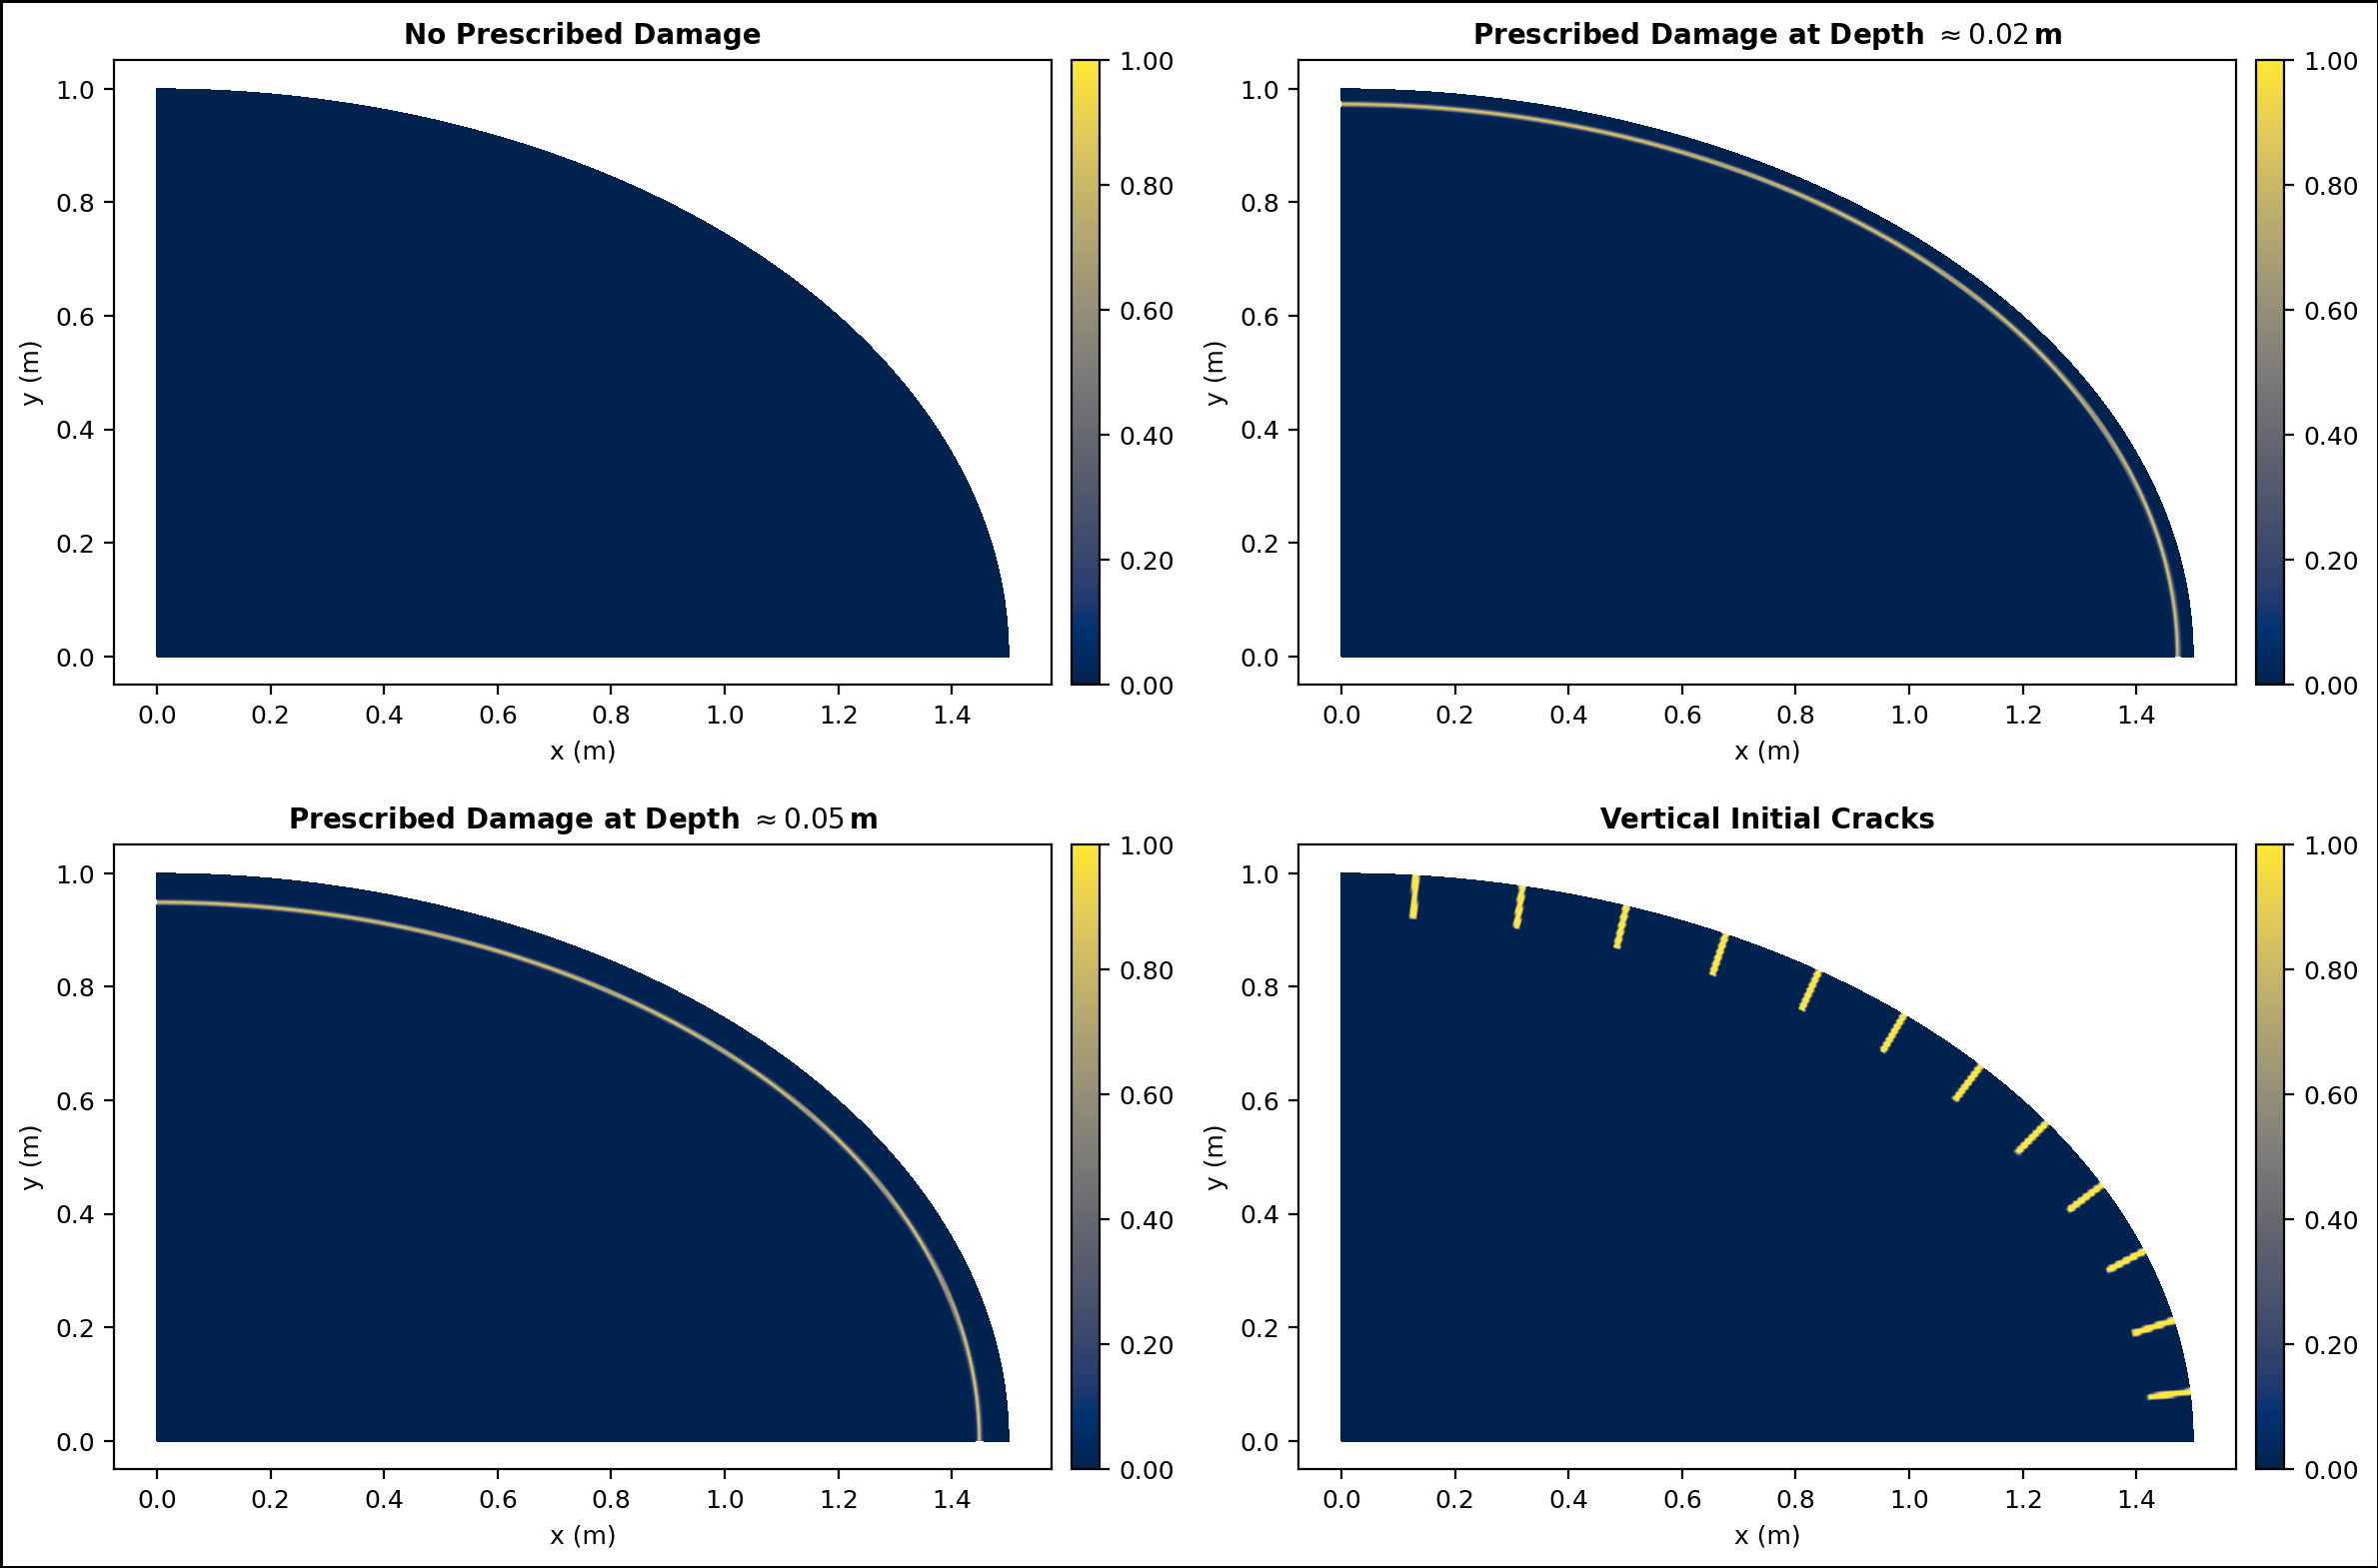

In [11]:
nr, nc = 2, 2
param_idx = 1
step = 0

fig, axes = plt.subplots(nr, nc, figsize=(nc * 6, nr * 4), dpi=200)
axes = axes.flatten()



# 注意：跳過 No Defect（從 profile[1:] 開始），對應 models[1:]
for i, (profile, model_name) in enumerate(zip(profiles, output_list[1])):

    nodes, connect_components, global_connection, node_vars, elet_vars, times = profile
        # 先取得色階範圍（從任一模型中抓即可）
    vmin = 0#node_vars[param_idx].min()
    vmax = 1#node_vars[param_idx].max()
    ax = axes[i]
    dispx=node_vars[2][step]
    dispy=node_vars[3][step]
    deform_nodes=nodes +np.stack([dispx,dispy]).T
    showNodePlot(
        deform_nodes, global_connection, node_vars[param_idx][step],
        titlelabel=["", node_var_labels[param_idx][1]],
        size=[6, 6], ax=ax, p_ext=[0.05, 0.05],
        colormap='cividis', e_notation=False,
        assign_bar_range=[vmin, vmax],
        x_unit=r'x (m)', y_unit=r'y (m)',
        font_adjust=1.5,manual_assign_range=True,x_mmax=1.5,x_mmin=0, y_mmax=1,y_mmin=0)
    ax.set_title(model_name, fontsize=10, fontweight="bold")
    
fig.patch.set_edgecolor('black')
fig.patch.set_linewidth(1.2)

plt.tight_layout()
plt.savefig(f"figs/fig4b{geo_model_name}_Initial_defects.png")
plt.savefig(f"figs/fig4b{geo_model_name}_Initial_defects.svg")
plt.show()


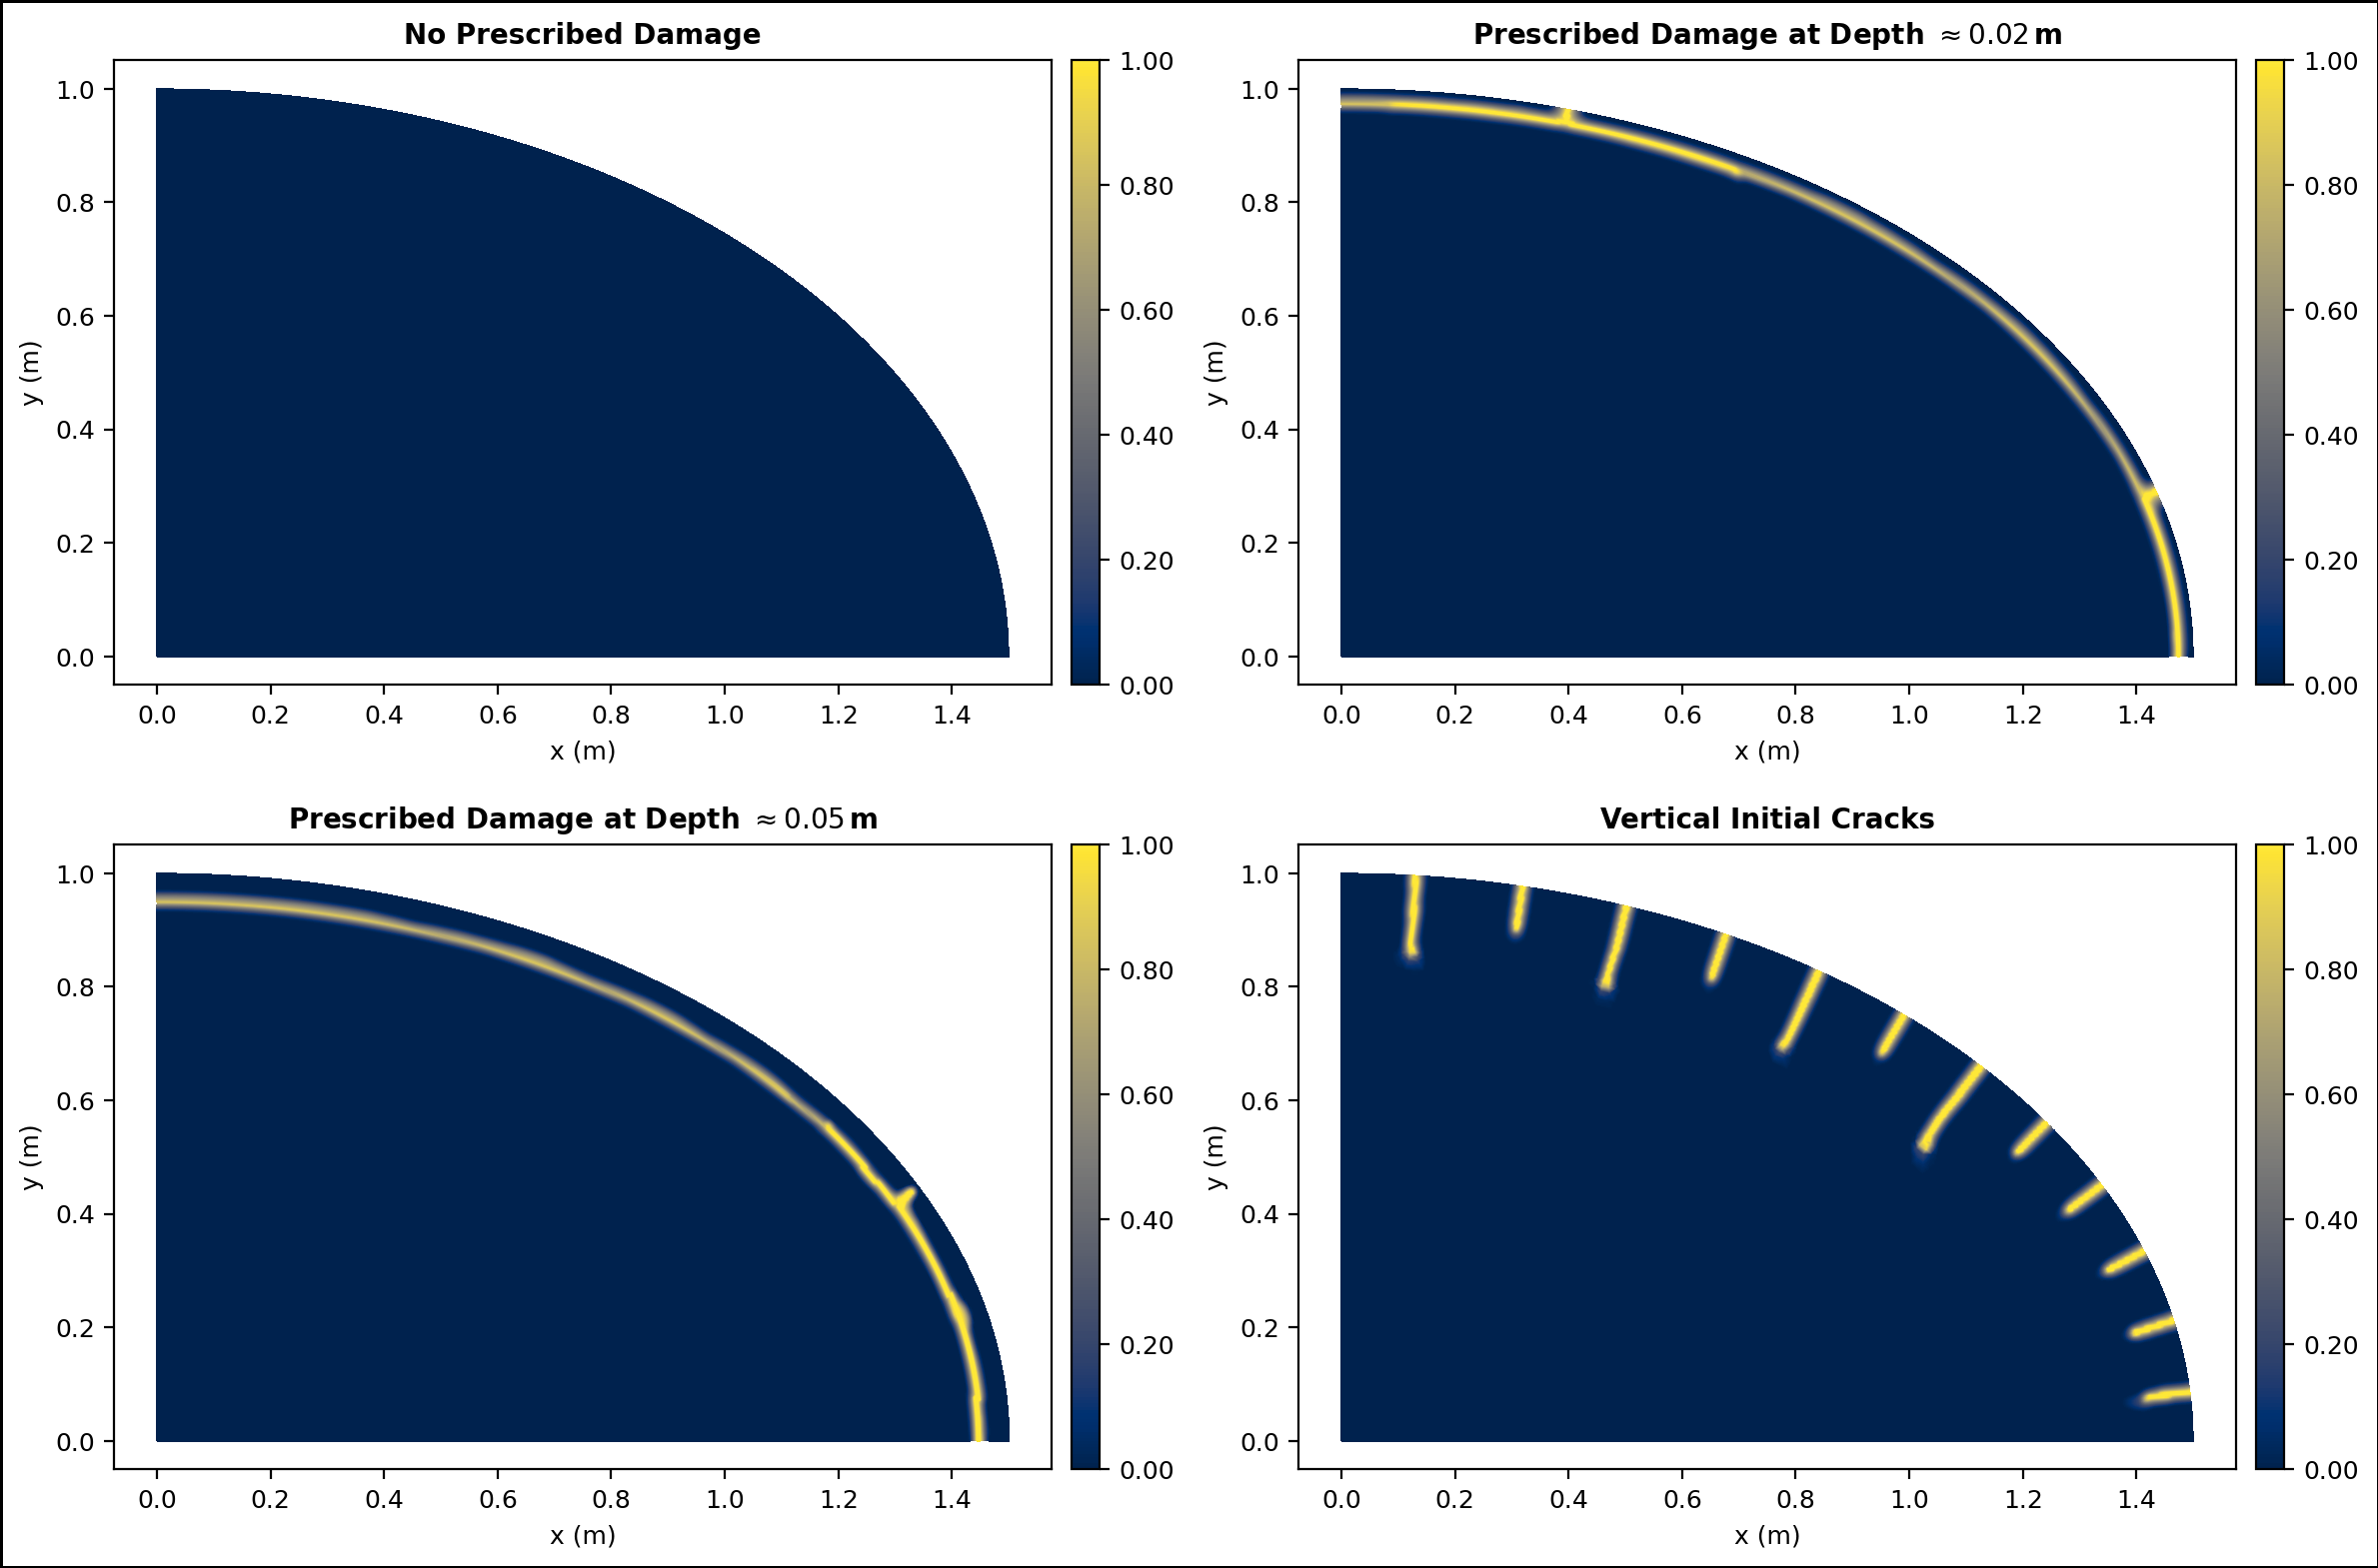

In [13]:
nr, nc = 2, 2
param_idx = 1
step = -1

fig, axes = plt.subplots(nr, nc, figsize=(nc * 6, nr * 4), dpi=200)
axes = axes.flatten()



# 注意：跳過 No Defect（從 profile[1:] 開始），對應 models[1:]
for i, (profile, model_name) in enumerate(zip(profiles, output_list[1])):

    nodes, connect_components, global_connection, node_vars, elet_vars, times = profile
        # 先取得色階範圍（從任一模型中抓即可）
    vmin = 0#node_vars[param_idx].min()
    vmax = 1#node_vars[param_idx].max()
    ax = axes[i]
    dispx=node_vars[2][step]
    dispy=node_vars[3][step]
    deform_nodes=nodes +np.stack([dispx,dispy]).T
    showNodePlot(
        deform_nodes, global_connection, node_vars[param_idx][step],
        titlelabel=["", node_var_labels[param_idx][1]],
        size=[6, 6], ax=ax, p_ext=[0.05, 0.05],
        colormap='cividis', e_notation=False,
        assign_bar_range=[vmin, vmax],
        x_unit=r'x (m)', y_unit=r'y (m)',
        font_adjust=1.5,manual_assign_range=True,x_mmax=1.5,x_mmin=0, y_mmax=1,y_mmin=0)
    ax.set_title(model_name, fontsize=10, fontweight="bold")
fig.patch.set_edgecolor('black')
fig.patch.set_linewidth(1.2)

plt.tight_layout()
plt.savefig(f'figs/fig6a{geo_model_name}_final_failure.png')
plt.savefig(f'figs/fig6a{geo_model_name}_failure.svg')
plt.show()